# 06 — Cluster Analysis: Grouping Similar Bookings

A **cluster** is a collection of data objects which are similar to one another within the same cluster
and dissimilar to the objects in other clusters.

Cluster analysis is **unsupervised learning**: there are no predefined classes.

In this notebook:
- **Partitioning method:** K-Means
- **Hierarchical method:** Agglomerative clustering (AGNES) and the dendrogram
- **Evaluation:** Elbow method and silhouette coefficient

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

BLUE, CYAN, GREEN, ORANGE = "#2563eb", "#06b6d4", "#10b981", "#f97316"
COLORS = [BLUE, ORANGE, GREEN, "#a855f7"]
FIG_DIR = Path("../figures")
pd.set_option("display.width", 200)

df = pd.read_csv("../data/processed/hotel_bookings_final.csv")
print(df.shape)

(86620, 41)


## 1. Attributes for Clustering

K-Means divides **numerical data** into K clusters, so five numerical attributes that describe the booking are used.
The class label `is_canceled` is **not** used to build the clusters; it is only used afterwards to describe them.

In [2]:
ATTRIBUTES = ["lead_time", "total_nights", "adr", "total_guests", "total_of_special_requests"]

df[ATTRIBUTES].describe().round(1)

,lead_time,total_nights,adr,total_guests,total_of_special_requests
count,86620.0,86620.0,86620.0,86620.0,86620.0
mean,80.3,3.7,107.2,2.0,0.7
std,86.0,2.7,51.3,0.7,0.8
min,0.0,1.0,0.0,1.0,0.0
25%,12.0,2.0,72.9,2.0,0.0
50%,50.0,3.0,99.0,2.0,0.0
75%,125.0,5.0,134.5,2.0,1.0
max,709.0,69.0,510.0,5.0,5.0


## 2. Normalise the Attributes

Clustering groups points by **distance** (e.g. Euclidean distance).
Without normalisation, `lead_time` (0–709) would dominate `total_of_special_requests` (0–5).

In [3]:
scaler = MinMaxScaler()
X = scaler.fit_transform(df[ATTRIBUTES])

pd.DataFrame(X, columns=ATTRIBUTES).describe().round(2)

,lead_time,total_nights,adr,total_guests,total_of_special_requests
count,86620.00,86620.00,86620.00,86620.00,86620.00
mean,0.11,0.04,0.21,0.26,0.14
std,0.12,0.04,0.10,0.18,0.17
min,0.00,0.00,0.00,0.00,0.00
25%,0.02,0.01,0.14,0.25,0.00
50%,0.07,0.03,0.19,0.25,0.00
75%,0.18,0.06,0.26,0.25,0.20
max,1.00,1.00,1.00,1.00,1.00


## 3. K-Means Clustering

K-Means represents each cluster by a **centroid** (the mean of its data points):
1. **Initialise:** choose K initial centroids
2. **Assign:** assign each data point to the cluster with the nearest centroid
3. **Update:** recalculate each centroid using the mean of the points assigned to its cluster
4. **Repeat** steps 2–3 until the clusters stop changing

**Goal:** minimise the Sum of Squared Errors

$$SSE(C) = \sum_{k=1}^{K}\sum_{x_i \in C_k} \lVert x_i - c_k \rVert^2$$

Different initial centroids can produce different results, so the initial centroids are chosen with **K-Means++**
(the default in scikit-learn), and the algorithm is run 10 times (`n_init=10`), keeping the run with the lowest SSE.

### 3.1 Determining the Number of Clusters

- **Empirical method:** $k \approx \sqrt{n/2}$
- **Elbow method:** use the turning point in the curve of the within-cluster sum of squares (SSE) against the number of clusters
- **Silhouette coefficient:** measures how compact and how well separated the clusters are (from −1 to 1, higher is better)

In [4]:
n = len(X)
print("Empirical method: k ≈ sqrt(n/2) =", round(np.sqrt(n / 2)))

Empirical method: k ≈ sqrt(n/2) = 208


In [5]:
sse = {}
silhouette = {}

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    sse[k] = km.inertia_                                    # SSE
    silhouette[k] = silhouette_score(X, km.labels_, sample_size=10000, random_state=42)

pd.DataFrame({"SSE": sse, "Silhouette": silhouette}).round(3)

,SSE,Silhouette
2,5382.785,0.258
3,4092.278,0.300
4,3411.500,0.323
5,2848.041,0.321
6,2475.170,0.319
7,2211.618,0.335
8,2047.455,0.345
9,1897.175,0.350
10,1764.740,0.368


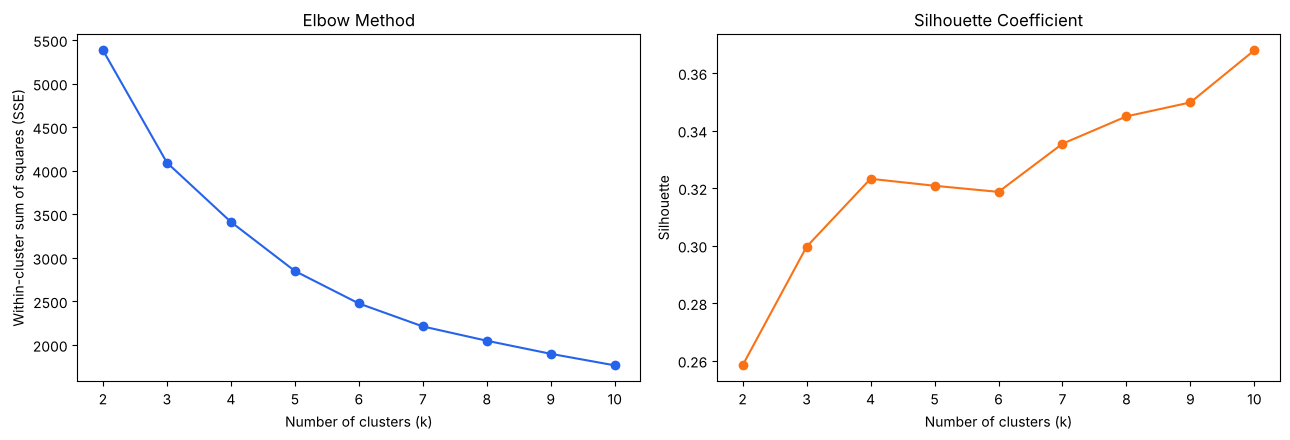

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(sse.keys()), list(sse.values()), marker="o", color=BLUE)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within-cluster sum of squares (SSE)")

axes[1].plot(list(silhouette.keys()), list(silhouette.values()), marker="o", color=ORANGE)
axes[1].set_title("Silhouette Coefficient")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.savefig(FIG_DIR / "clu_01_elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Final K-Means Model (k = 4)

The empirical method gives about 208 clusters, which is too many to summarise the data.
The SSE curve bends at **k = 4**: after 4, adding a cluster gives only a small reduction in SSE.

In [7]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X)

print("SSE:", round(kmeans.inertia_, 1))
print("Silhouette:", round(silhouette_score(X, df["cluster"], sample_size=10000, random_state=42), 3))
df["cluster"].value_counts().sort_index()

SSE: 3411.5


Silhouette: 0.323


cluster
0    10797
1    14541
2    13762
3    47520
Name: count, dtype: int64

### 3.3 Describing the Clusters

Each centroid is shown in the original units (mean of each attribute in the cluster),
together with the cancellation rate of the cluster.

In [8]:
profile = df.groupby("cluster")[ATTRIBUTES + ["is_canceled"]].mean().round(2)
profile["bookings"] = df["cluster"].value_counts().sort_index()
profile

,lead_time,total_nights,adr,total_guests,total_of_special_requests,is_canceled,bookings
cluster,,,,,,,
0,89.38,3.88,161.32,3.37,0.52,0.39,10797
1,47.95,2.69,78.78,1.00,0.26,0.19,14541
2,87.92,3.86,117.61,2.15,2.22,0.20,13762
3,85.84,3.84,100.59,2.00,0.44,0.30,47520


### 3.4 Cluster Visualisation

The centroids (normalised values from 0 to 1) show which attributes separate the clusters.

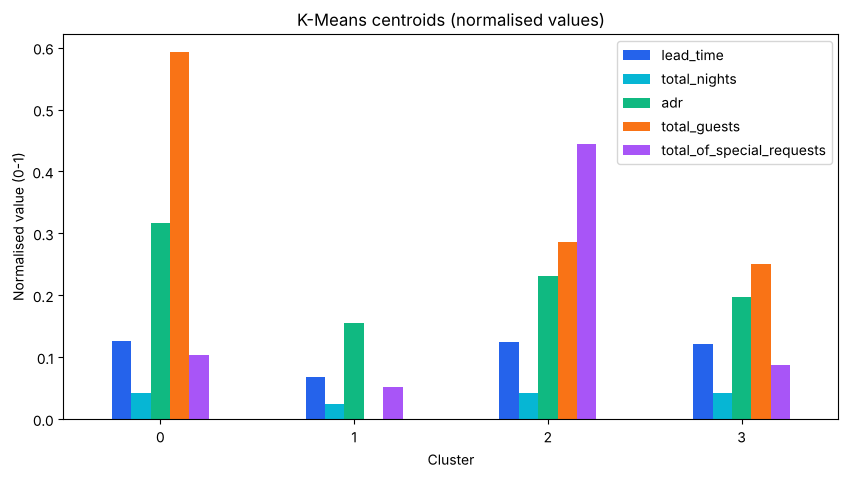

In [9]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=ATTRIBUTES)

centers.plot(kind="bar", figsize=(10, 5), color=[BLUE, CYAN, GREEN, ORANGE, "#a855f7"])
plt.title("K-Means centroids (normalised values)")
plt.xlabel("Cluster")
plt.ylabel("Normalised value (0-1)")
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.savefig(FIG_DIR / "clu_02_kmeans_centroids.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Hierarchical Clustering: Agglomerative (AGNES)

- Start with singleton clusters and continuously **merge the two closest clusters** (bottom-up)
- The result is drawn as a **dendrogram**; cutting it at a level gives the clusters
- The distance between two clusters depends on the link:
  - **Single link:** the nearest members (sensitive to noise and outliers)
  - **Complete link:** the most dissimilar members (compact clusters)
  - **Average link:** the average distance over all pairs

The time complexity is at least $O(n^2)$, so a random sample of 2,000 bookings is used.

In [10]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X), 2000, replace=False)
X_sample = X[idx]

for link in ["single", "complete", "average"]:
    agnes = AgglomerativeClustering(n_clusters=4, linkage=link)
    labels = agnes.fit_predict(X_sample)
    print(f"{link:9s} cluster sizes: {np.bincount(labels)} | silhouette: {silhouette_score(X_sample, labels):.3f}")

single    cluster sizes: [1997    1    1    1] | silhouette: 0.399
complete  cluster sizes: [ 339 1169  191  301] | silhouette: 0.128


average   cluster sizes: [1995    3    1    1] | silhouette: 0.322


**Single** and **average** link put almost all bookings in one cluster and isolate a few unusual bookings
as clusters of size 1 — they are sensitive to outliers. Their high silhouette is therefore misleading.
**Complete link** produces more useful groups, so it is used for the dendrogram.

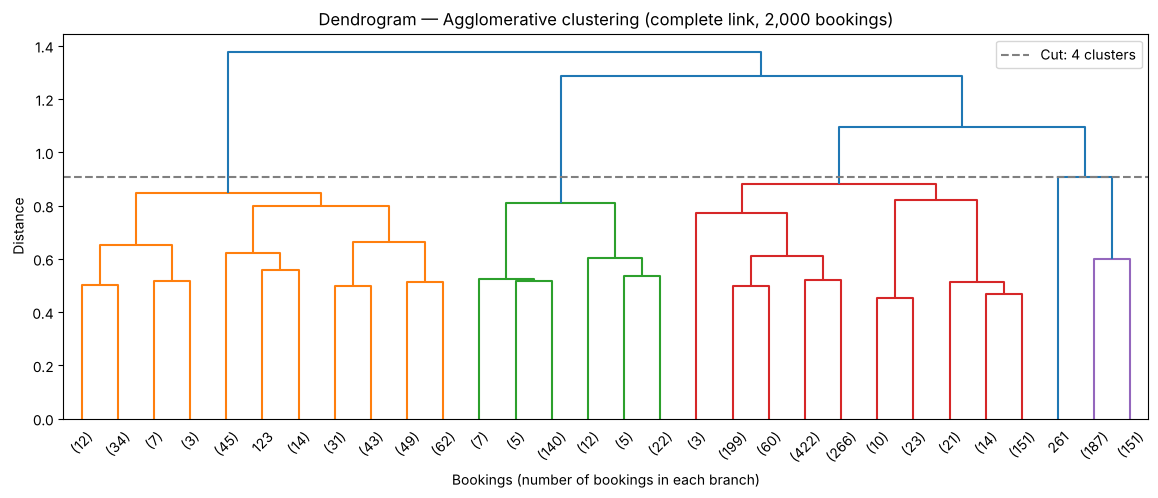

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_sample, method="complete")

plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-4, 2])
plt.axhline(Z[-4, 2], color="grey", ls="--", label="Cut: 4 clusters")
plt.title("Dendrogram — Agglomerative clustering (complete link, 2,000 bookings)")
plt.xlabel("Bookings (number of bookings in each branch)")
plt.ylabel("Distance")
plt.legend()
plt.savefig(FIG_DIR / "clu_03_dendrogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
agnes = AgglomerativeClustering(n_clusters=4, linkage="complete")
agnes_labels = agnes.fit_predict(X_sample)

print("Silhouette on the same 2,000 bookings:")
print("  K-Means:               ", round(silhouette_score(X_sample, df["cluster"].values[idx]), 3))
print("  Agglomerative (complete):", round(silhouette_score(X_sample, agnes_labels), 3))

Silhouette on the same 2,000 bookings:
  K-Means:                0.32
  Agglomerative (complete): 0.128


## 5. Summary

**Question:** What groups of similar bookings exist, and do they differ in cancellation?

| Cluster | Bookings | Description | Cancellation rate |
|---|---|---|---|
| 0 | 10,797 | **families / groups** (≈3.4 guests), highest price (≈€161) | **39%** |
| 1 | 14,541 | **single guests**, lowest price (≈€79), shortest lead time | **19%** |
| 2 | 13,762 | **2 or more special requests** | 20% |
| 3 | 47,520 | typical couples (2 guests, ≈€101), few requests | 30% |

**Findings**
1. K-Means (k = 4, chosen with the elbow method) separates bookings mainly by **number of guests**, **price** and **special requests**.
2. Large, expensive bookings (cluster 0) are canceled most often (39%); single guests and guests with special requests are canceled least (19–20%).
3. Special requests are linked to fewer cancellations here and in the classification models (notebook 05), found here **without using the class label**.
4. Agglomerative clustering with **single** or **average** link isolates a few unusual bookings (sensitive to outliers); **complete** link gives four usable groups but a much lower silhouette (0.128) than K-Means (0.320) on the same sample.

**Limitation:** the silhouette coefficient is about 0.32, so the clusters are only moderately separated.